# Метки, время и дрейф

Часть EDA по датасету Elliptic. Ноутбук состоит из пяти разделов:

1. **Метки.** Сколько у нас незаконных (illicit), легальных (licit) и неразмеченных (unknown) транзакций и на что похожи unknown.
2. **Время.** Как транзакции и доля незаконных транзакций распределены по 49 временным шагам.
3. **Дрейф.** Меняются ли признаки со временем. Если да, модель, обученная на "прошлом", может хуже работать на "будущем".
4. **Разбиение.** Как делить данные на train и test с учётом времени.
5. **Выводы.** Что из всего этого следует для моделей.

In [1]:
from bitcoin_aml_detection.data import FEATURES, LOCAL_FEATURES, AGG_FEATURES, load_txs
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

df = load_txs()

In [2]:
COLORS = {
    "illicit": "#e76f51",
    "licit": "#2a9d8f",
    "unknown": "#b0b0b0",
}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.ymargin": 0.15,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "font.size": 11,
})

## 1. Метки и неразмеченные транзакции

Сначала посмотрим, сколько всего транзакций в датасете.

In [3]:
print(f'Всего транзакций: {len(df)}')

Всего транзакций: 203769


Посчитаем, сколько транзакций каждого типа и какую долю от всего датасета они составляют.

In [4]:
classes = ["illicit", "licit", "unknown"]

counts = df["label"].value_counts()[classes]
shares = df["label"].value_counts(normalize=True)[classes]

label_table = pd.DataFrame({
    "транзакций": counts,
    "доля от всех": shares.round(3),
})

label_table

,транзакций,доля от всех
label,,
illicit,4545,0.022
licit,42019,0.206
unknown,157205,0.771


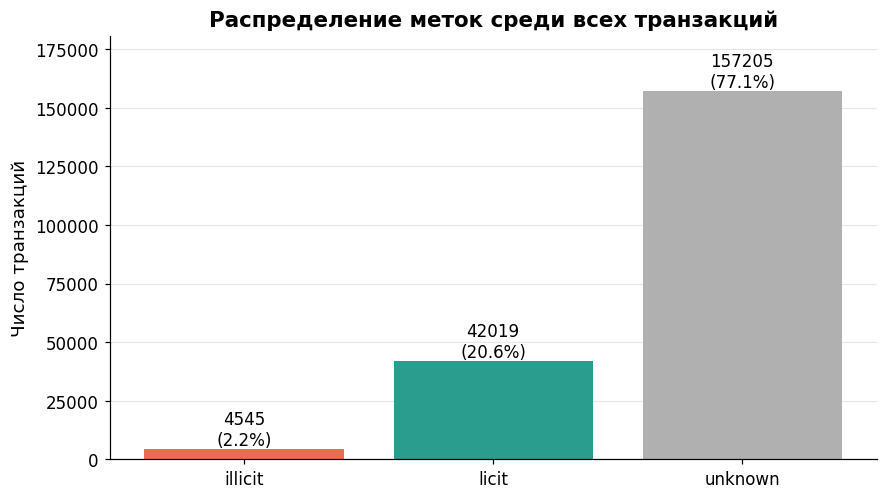

In [5]:
labels = [f"{n}\n({share:.1%})" for n, share in zip(counts.values, shares.values)]

bars = plt.bar(counts.index, counts.values,
               color=[COLORS[c] for c in counts.index])
plt.bar_label(bars, labels=labels)
plt.title("Распределение меток среди всех транзакций")
plt.ylabel("Число транзакций")
plt.show()

**Что видим на графике:**

- Размеченных данных немного: метка есть только у 23% транзакций, у остальных 77% метки нет (unknown).

- Незаконных транзакций всего 4 545, это 2.2% от всего датасета.

- Легальных транзакций 42 019, это 20.6% от всего датасета.

Про unknown мы не знаем, легальные они или нет. Там могут быть и те, и другие. Для обычного обучения с учителем они не подходят, но пригодятся в semi-supervised подходах.

Посмотрим только на размеченные транзакции:

In [6]:
labeled_classes = ["illicit", "licit"]

# оставляем только строки, где метка известна
labeled = df[df["label"] != "unknown"]

labeled_counts = labeled["label"].value_counts()[labeled_classes]
labeled_shares = labeled["label"].value_counts(normalize=True)[labeled_classes]

labeled_table = pd.DataFrame({
    "транзакций": labeled_counts,
    "доля среди размеченных": labeled_shares.round(3),
})

In [7]:
print(f"Размеченных транзакций: {len(labeled)}")

Размеченных транзакций: 46564


In [8]:
labeled_table

,транзакций,доля среди размеченных
label,,
illicit,4545,0.098
licit,42019,0.902


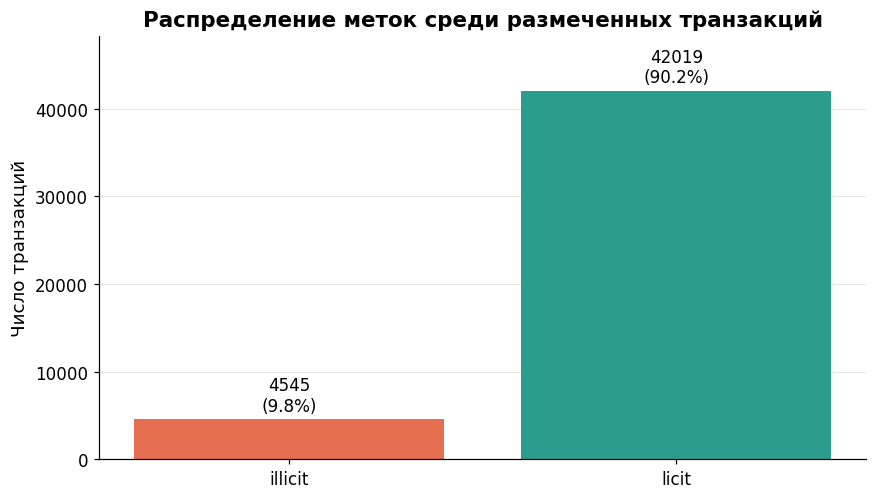

In [9]:
labels = [f"{n}\n({share:.1%})" for n, share in zip(labeled_counts.values, labeled_shares.values)]

bars = plt.bar(labeled_counts.index, labeled_counts.values,
               color=[COLORS[c] for c in labeled_counts.index])
plt.bar_label(bars, labels=labels, padding=3)
plt.title("Распределение меток среди размеченных транзакций")
plt.ylabel("Число транзакций")
plt.show()

**Что видим на графике:**

- Среди размеченных транзакций незаконных 4 545, это 9.8%.
- Легальных транзакций 42 019, это 90.2%.
- На одну незаконную транзакцию приходится примерно 9 легальных, так что классы сильно несбалансированы.

Из-за этого accuracy не подходит как метрика: модель, которая всегда отвечает "licit", угадает 90% транзакций и не найдёт ни одной незаконной. Поэтому качество моделей будем оценивать по precision, recall, F1 и PR-AUC для класса illicit.

### Что такое unknown

Пропущенные значения в датасете встречаются только в столбце с таргетом `y`. Это как раз unknown, 157 205 транзакций (77.1%), в признаках пропусков нет. Выше было отмечено, что про unknown неизвестно, легальные они или нет. Но можно попытаться разобраться, почему у них нет метки и на какой класс они больше похожи по признакам.

Сначала важно понять, **откуда берутся метки**. В статье про датасет ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)) транзакция считается licit, если тот, кто её отправил (владелец ключей от входных адресов), относится к легальной категории вроде бирж, кошельков, майнеров и легальных сервисов. Если отправитель связан со скамом, вредоносным ПО, ransomware, финансовыми пирамидами или террористическими организациями, транзакция считается illicit. Про остальные транзакции авторы пишут только, что метки у них нет, и не объясняют почему.

Ещё авторы упоминают, что при разметке использовались эвристики. Например, много входов и повторное использование адресов обычно говорят о легальном участнике вроде биржи, а у незаконных транзакций входов чаще меньше. Значит, метка могла появиться у транзакции в том числе из-за её признаков, и размеченные транзакции могут заметно отличаться от неразмеченных.

Получается, что метку ставили не наугад, а только тем транзакциям, которые удалось связать с известным участником, и в том числе по их признакам.

**Гипотеза:** Пропуски в `y` не случайны. Unknown по признакам отличаются от размеченных транзакций и не являются обычной смесью licit и illicit.

Если бы метки, наоборот, пропускали случайно, unknown выглядели бы как обычная смесь licit и illicit, то есть в основном как licit, ведь незаконных транзакций мало. Проверим, так ли это.

Сначала найдём признаки, по которым licit и illicit различаются. Для этого для каждого признака посчитаем статистику Колмогорова-Смирнова (KS). Она сравнивает два распределения и показывает самый большой разрыв между ними. 0 значит, что распределения совпадают, а чем ближе к 1, тем сильнее они различаются. Подробнее о статистике в разделе 3, где она понадобится для анализа дрейфа.

In [10]:
licit_df = df[df["label"] == "licit"]
illicit_df = df[df["label"] == "illicit"]

ks_licit_illicit = []

for feature in FEATURES:
    ks = ks_2samp(licit_df[feature], illicit_df[feature]).statistic
    ks_licit_illicit.append({"feature": feature, "KS": ks})

ks_licit_illicit = pd.DataFrame(ks_licit_illicit).sort_values("KS", ascending=False)

ks_licit_illicit.head()

,feature,KS
52,local_53,0.617084
54,local_55,0.613535
40,local_41,0.594959
46,local_47,0.593686
89,local_90,0.593160


Возьмём признаки, по которым licit и illicit заметно различаются (KS > 0.2). Если бы unknown были обычной смесью, где около 90% licit, то на каждом таком признаке они были бы ближе к licit, чем к illicit. Посчитаем, так ли это.

In [11]:
unknown_df = df[df["label"] == "unknown"]

# признаки, по которым licit и illicit заметно различаются
strong_features = ks_licit_illicit[ks_licit_illicit["KS"] > 0.2]["feature"]

closer_to_licit = 0
closer_to_illicit = 0

for feature in strong_features:
    ks_to_licit = ks_2samp(unknown_df[feature], licit_df[feature]).statistic
    ks_to_illicit = ks_2samp(unknown_df[feature], illicit_df[feature]).statistic

    if ks_to_licit < ks_to_illicit:
        closer_to_licit += 1
    else:
        closer_to_illicit += 1


In [12]:
print(f"Признаков, где licit и illicit заметно различаются: {len(strong_features)}")
print(f"Из них unknown ближе к licit: {closer_to_licit}")
print(f"Из них unknown ближе к illicit: {closer_to_illicit}")

Признаков, где licit и illicit заметно различаются: 113
Из них unknown ближе к licit: 68
Из них unknown ближе к illicit: 45


**Что видим:**

- Из 113 признаков, по которым licit и illicit заметно различаются, unknown ближе к licit на 68, а ближе к illicit на 45.
- Если бы unknown были обычной смесью, где около 90% licit, ближе к illicit они не оказались бы почти ни на одном признаке. А таких признаков 45, это примерно 40%.

Значит, гипотеза подтверждается, пропуски в метке не случайны. Unknown - это не просто транзакции, которым забыли поставить метку, а транзакции, которые по своим свойствам отличаются от размеченных.

Поэтому пропуски в `y` мы не заполняем. Модели с учителем обучаем только на размеченных транзакциях, а unknown используем в semi-supervised подходах, учитывая, что они отличаются от размеченных.

**Итого:** размечено около 23% транзакций, а среди размеченных незаконных транзакций всего около 10%, так что классы сильно несбалансированы. Остальные 77% - unknown, и пропуски в их метке не случайны, по признакам они заметно отличаются от размеченных транзакций. Поэтому для моделей с учителем используем только размеченные данные, а unknown пригодятся в semi-supervised подходах.

## 2. Транзакции во времени

Каждая транзакция относится к одному из 49 временных шагов. Один шаг - это примерно две недели. Посмотрим, как транзакции распределены по шагам и меняется ли со временем доля незаконных.

Сначала посчитаем, сколько транзакций каждого типа приходится на каждый шаг.

In [13]:
# crosstab считает, сколько транзакций каждого типа на каждом шаге
by_step = pd.crosstab(df["time_step"], df["label"])[classes]

by_step.head(10)

label,illicit,licit,unknown
time_step,,,
1,17,2130,5733
2,18,1099,3427
3,11,1268,5342
4,30,1410,4253
5,8,1874,4921
6,5,480,3843
7,102,1101,4845
8,67,1098,3292
9,248,530,4218


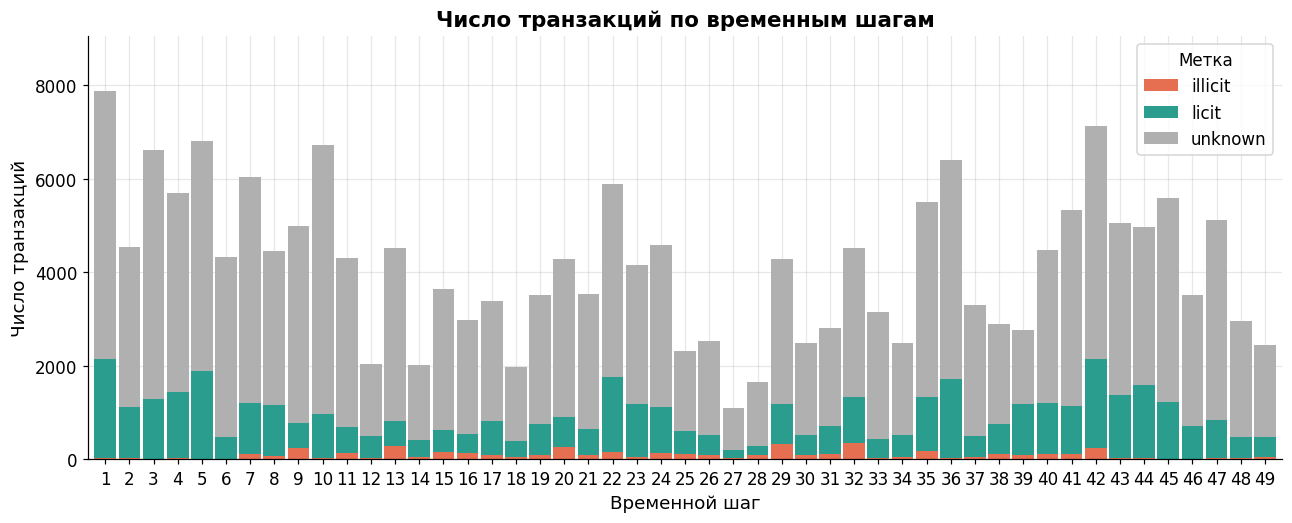

In [14]:
ax = by_step.plot(kind="bar", stacked=True, width=0.9, figsize=(14, 5),
                  color=[COLORS[c] for c in classes])

plt.xticks(rotation=0)
plt.title("Число транзакций по временным шагам")
plt.xlabel("Временной шаг")
plt.ylabel("Число транзакций")
plt.legend(title="Метка")
plt.show()

**Что видим на графике:**

- Число транзакций на шаге сильно скачет: от примерно 1 000 (шаг 27) до почти 8 000 (шаг 1).
- На каждом шаге большую часть составляют unknown, размеченных обычно примерно меньше трети.
- Незаконных транзакций так мало, что на графике их почти не видно. Поэтому долю illicit по шагам надо посмотреть отдельно.

Посмотрим, какую долю незаконные транзакции составляют среди размеченных на каждом шаге.

In [15]:
# illicit y = 1, licit y = 0, поэтому среднее y на шаге = доля illicit
illicit_share = labeled.groupby("time_step")["y"].mean() * 100

In [16]:
illicit_share.head(15)

time_step
1      0.791803
2      1.611459
3      0.860047
4      2.083333
5      0.425080
6      1.030928
7      8.478803
8      5.751073
9     31.876607
10     1.851852
11    18.821839
12     3.162055
13    35.970334
14    10.311751
15    23.786408
Name: y, dtype: float64

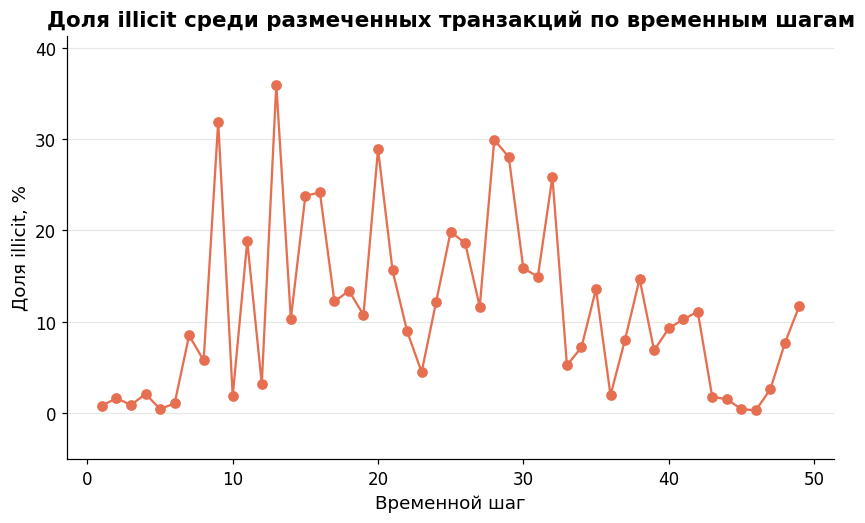

In [17]:
plt.plot(illicit_share.index, illicit_share.values,
         marker="o", color=COLORS["illicit"])
plt.title("Доля illicit среди размеченных транзакций по временным шагам")
plt.xlabel("Временной шаг")
plt.ylabel("Доля illicit, %")
plt.show()

**Что видим на графике:**

- Доля illicit от шага к шагу меняется очень сильно: от почти 0% до 36% (шаг 13).
- На первых шагах (1-6) незаконных транзакций почти нет, около 2% и меньше.
- С 43-го шага доля illicit резко падает почти до нуля и только к последним шагам снова немного поднимается. Авторы датасета ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)) объясняют это закрытием крупного даркнет-рынка на 43-м шаге. После него все модели начинают работать плохо, даже если их переобучать на каждом новом шаге.

Получается, что данные со временем меняются, поэтому случайное разбиение на train и test здесь не подходит, делить нужно по времени. Также качество модели на тесте лучше смотреть не только в целом, но и отдельно по каждому шагу. Так будет видно, на каких шагах модель работает хорошо, а на каких плохо.

**Итого:** транзакции распределены по шагам неравномерно, их число сильно скачет от шага к шагу. Доля незаконных транзакций со временем тоже не постоянна, на первых шагах их почти нет, в середине бывает до 30% и больше, а с 43-го шага доля резко падает почти до нуля и только к последним шагам снова немного поднимается. Значит, данные меняются со временем, и это нужно учитывать при разбиении на train и test.

## 3. Временной дрейф

**Временной дрейф** - это когда данные со временем меняются, и модель, обученная на прошлом, начинает хуже работать на будущем.

Меняться может разное. Может измениться доля классов: например, незаконных транзакций станет меньше. Могут измениться сами признаки: транзакции в целом начнут выглядеть иначе. Может измениться то, чем незаконные транзакции отличаются от легальных: мошенники сменят тактику, и старые закономерности перестанут работать.

Изменение доли классов мы уже видели в прошлом разделе. Здесь проверим, меняются ли со временем сами признаки.


Что именно означает каждый признак, **неизвестно**, так как Elliptic не раскрывает это из-за коммерческой тайны. Известно только, что локальные признаки описывают саму транзакцию (число входов и выходов, комиссию, объём перевода и т. п.), а агрегированные - её соседей в графе. Поэтому мы увидим, какие признаки сдвинулись со временем, но не сможем сказать, что именно за ними стоит.

Для сравнения делим шаги на **два периода**: ранние (1-34) и поздние (35-49). Это стандартная граница из статьи про датасет, её же потом используем для train/test split.

In [18]:
print(f"Всего признаков: {len(FEATURES)}")
print(f"Локальных: {len(LOCAL_FEATURES)}")
print(f"Агрегированных: {len(AGG_FEATURES)}")

Всего признаков: 165
Локальных: 93
Агрегированных: 72


In [19]:
early = df[df["time_step"] <= 34]
late = df[df["time_step"] >= 35]

early_share = len(early) / len(df) * 100
late_share = len(late) / len(df) * 100

print(f"Ранние шаги (1-34): {len(early)} транзакций ({early_share:.1f}%)")
print(f"Поздние шаги (35-49): {len(late)} транзакций ({late_share:.1f}%)")

Ранние шаги (1-34): 136265 транзакций (66.9%)
Поздние шаги (35-49): 67504 транзакций (33.1%)


Для каждого признака сравним его распределение в ранних и поздних шагах с помощью статистики Колмогорова-Смирнова (KS), которую мы уже использовали в разделе 1. Разберём подробнее, как она считается.

Она показывает максимальный разрыв между двумя распределениями, 0 значит, что распределения совпадают, а чем ближе к 1, тем сильнее они различаются.

$$
D = \max_x \left| F_{\text{ранние}}(x) - F_{\text{поздние}}(x) \right|
$$

Здесь $x$ - любое значение признака, $F(x)$ - доля значений признака, которые меньше или равны $x$. Для каждого периода строится такая кривая, и $D$ - это самое большое расстояние между ними по вертикали, если перебрать все возможные $x$.

Был выбран KS, потому что он сравнивает распределения целиком, а не только средние, не требует, чтобы данные были нормально распределены, и всегда даёт число от 0 до 1. Поэтому признаки можно сравнивать между собой и найти те, что дрейфуют сильнее всего.

In [20]:
ks_results = []

for feature in FEATURES:
    result = ks_2samp(early[feature], late[feature])
    ks_results.append({"feature": feature, "KS": result.statistic})

drift = pd.DataFrame(ks_results).sort_values("KS", ascending=False)

drift.head(15)

,feature,KS
135,agg_43,0.996319
100,agg_8,0.995941
102,agg_10,0.994667
99,agg_7,0.992593
138,agg_46,0.965548
136,agg_44,0.930235
1,local_2,0.604995
105,agg_13,0.573018
108,agg_16,0.556302
106,agg_14,0.533597


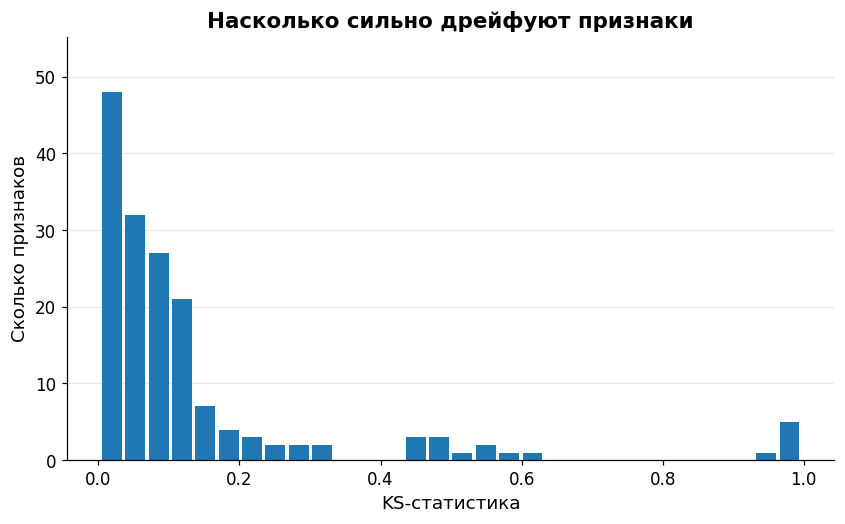

In [21]:
plt.hist(drift["KS"], bins=30, rwidth=0.85)
plt.title("Насколько сильно дрейфуют признаки")
plt.xlabel("KS-статистика")
plt.ylabel("Сколько признаков")
plt.show()

In [22]:
weak = (drift["KS"] < 0.1).sum()
small = ((drift["KS"] >= 0.1) & (drift["KS"] < 0.2)).sum()
noticeable = ((drift["KS"] >= 0.2) & (drift["KS"] < 0.4)).sum()
strong = ((drift["KS"] >= 0.4) & (drift["KS"] < 0.9)).sum()
extreme = (drift["KS"] >= 0.9).sum()

print(f"Почти не меняются (KS < 0.1): {weak}")
print(f"Слабый дрейф (0.1-0.2): {small}")
print(f"Заметный дрейф (0.2-0.4): {noticeable}")
print(f"Сильный дрейф (0.4-0.9): {strong}")
print(f"Распределения почти не пересекаются (KS >= 0.9): {extreme}")

Почти не меняются (KS < 0.1): 105
Слабый дрейф (0.1-0.2): 34
Заметный дрейф (0.2-0.4): 9
Сильный дрейф (0.4-0.9): 11
Распределения почти не пересекаются (KS >= 0.9): 6


**Что видим на графике:**

- Большинство признаков со временем меняются мало. У 105 признаков KS меньше 0.1, то есть они почти не меняются, ещё у 34 KS от 0.1 до 0.2, это слабый дрейф. Вместе это 139 из 165.
- У 20 признаков дрейф уже ощутимый. У 9 из них KS от 0.2 до 0.4, у 11 от 0.4 до 0.9.
- Справа особняком стоят 6 признаков с KS больше 0.9. Их значения в ранних и поздних шагах почти не пересекаются, и это выглядит подозрительно.

В целом признаки довольно стабильны, но часть из них со временем заметно сдвигается, и это может ухудшить качество модели на новых данных.

Пороги 0.1, 0.2, 0.4 и 0.9 были выбраны для удобства, общепринятой шкалы для KS нет.

### Как выглядит дрейф на примерах

KS сводит изменение признака к одному числу. Чтобы понять, что за ним стоит, посмотрим на три признака с разным KS - почти без дрейфа, с сильным дрейфом и с самым большим KS.

Для каждого признака построим boxplot по шагам. Ящик показывает, где лежит средняя половина значений на шаге, линия внутри - медиану, усы - общий разброс.

In [23]:
def plot_box_by_step(feature):
    # для каждого шага собираем значения признака
    values_by_step = [df.loc[df["time_step"] == step, feature] for step in range(1, 50)]

    ks = drift.loc[drift["feature"] == feature, "KS"].iloc[0]

    plt.figure(figsize=(14, 5))
    plt.boxplot(values_by_step, showfliers=False)
    plt.axvline(34.5, color="gray", linestyle="--",
                label="граница ранних и поздних шагов")
    plt.title(f"Значения {feature} по временным шагам (KS = {ks:.2f})")
    plt.xlabel("Временной шаг")
    plt.ylabel("Значение признака")
    plt.legend()
    plt.show()

Для начала возьмём признак почти без дрейфа

In [24]:
drift[(drift["KS"] > 0.02) & (drift["KS"] < 0.05)].head(5)

,feature,KS
15,local_16,0.049869
95,agg_3,0.048366
139,agg_47,0.048347
17,local_18,0.047509
159,agg_67,0.046754


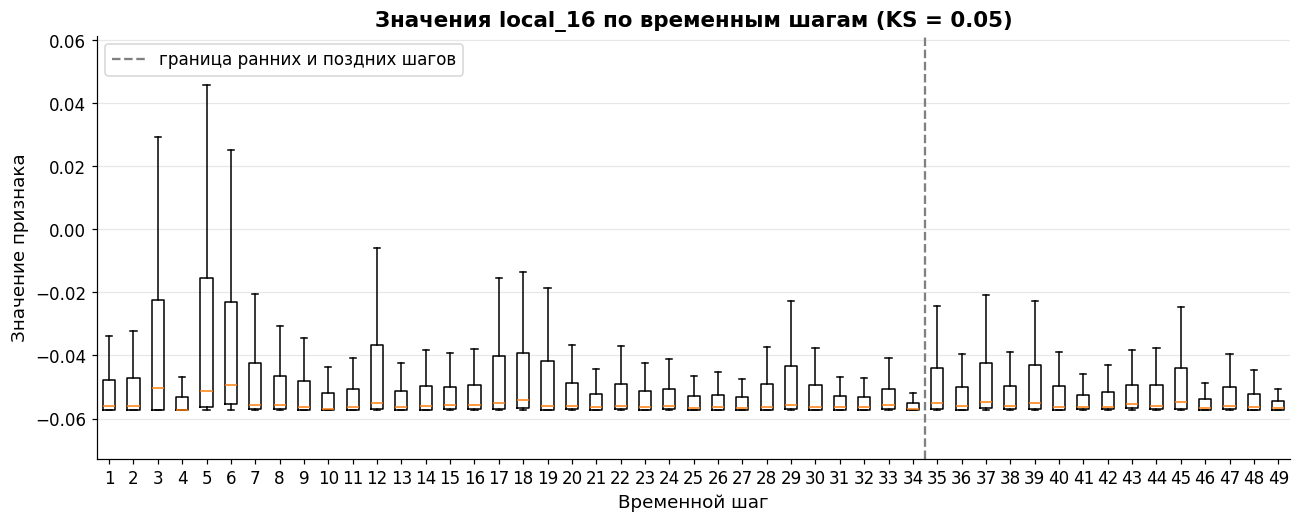

In [25]:
plot_box_by_step("local_16")

**Что видим на графике:**

- Медиана на всех шагах держится примерно на одном уровне у нижней границы значений.
- Размер ящиков и усов меняется от шага к шагу, на некоторых шагах (3, 5, 6, 12, 17-19) разброс заметно больше. Но это скачки, а не постепенное изменение.
- Слева и справа от границы картина примерно одинаковая, поздние шаги не выглядят как-то особенно.

Поэтому KS у этого признака маленький. Так выглядит признак без дрейфа, значения немного колеблются, но со временем систематически не меняются.

`local_2` - один из признаков с сильным дрейфом.

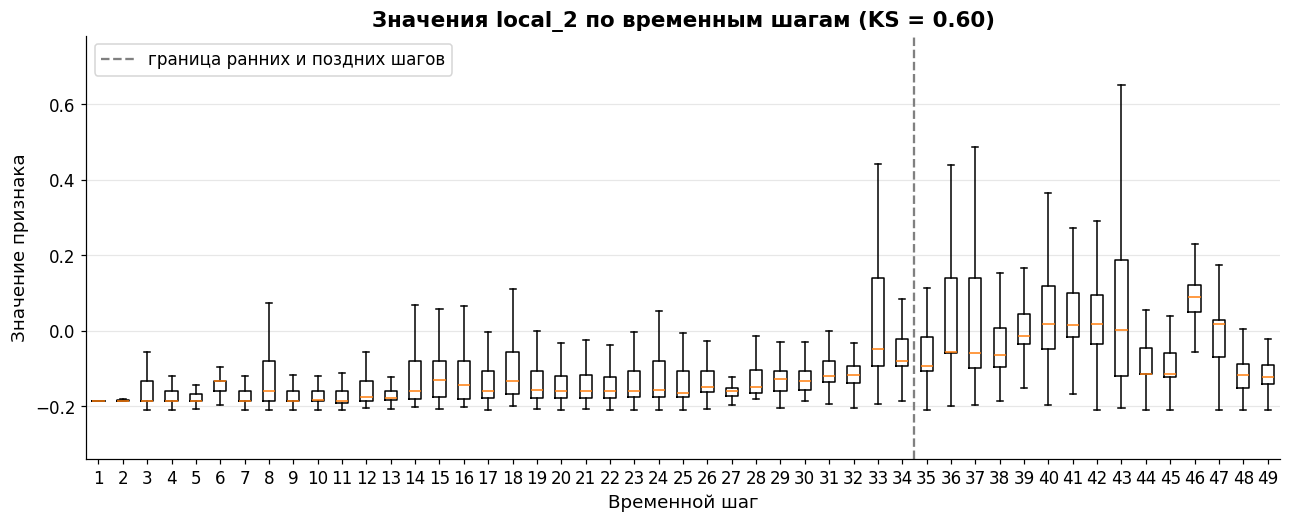

In [26]:
plot_box_by_step("local_2")

**Что видим на графике:**

- На шагах 1-32 значения `local_2` у большинства транзакций близки к минимуму, около -0.2, и почти не различаются. Разброс постепенно растёт, но остаётся небольшим.
- Примерно с 33-го шага признак резко меняется. Разброс становится намного больше, а медиана на шагах 40-43 поднимается почти до 0.
- После 43-го шага значения частично возвращаются вниз, но разброс всё равно больше, чем в начале.

Изменение начинается почти ровно на границе ранних и поздних шагов, поэтому KS у этого признака и получился таким большим. При обучении на шагах 1-34 модель почти не видит больших значений `local_2`, а на тестовых шагах они встречаются постоянно.

`agg_43` - признак с самым большим KS.

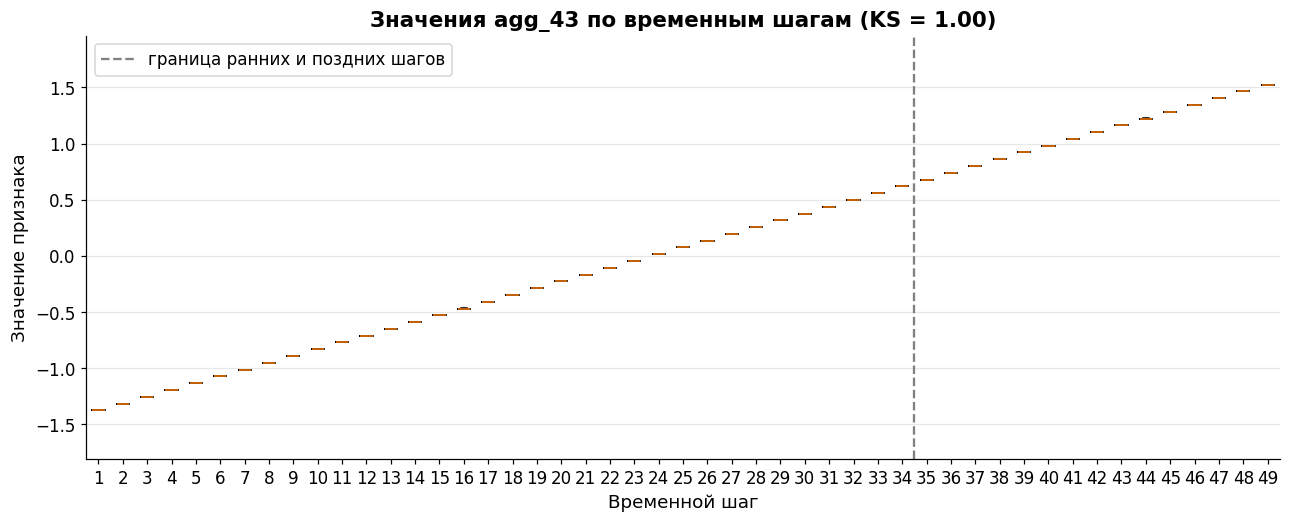

In [27]:
plot_box_by_step("agg_43")

**Что видим на графике:**

- На каждом шаге ящик сжат в тонкую чёрточку, то есть почти у всех транзакций шага значение `agg_43` одинаковое.
- От шага к шагу значение растёт ровно, каждый раз на одну и ту же величину, как будто это просто номер шага в другом масштабе.

Для сравнения, у `local_2` внутри шага большой разброс, а меняется он скачками. Здесь же никакого разброса нет, только ровная лесенка.

### Признаки с KS больше 0.9

У шести признаков KS больше 0.9, то есть их значения в ранних и поздних шагах почти не пересекаются. Для обычной характеристики транзакции это очень странно, поэтому разберёмся с ними отдельно.

In [28]:
strange = list(drift[drift["KS"] > 0.9]["feature"])

print(f"Признаков с KS > 0.9: {len(strange)}")
drift[drift["KS"] > 0.9]

Признаков с KS > 0.9: 6


,feature,KS
135,agg_43,0.996319
100,agg_8,0.995941
102,agg_10,0.994667
99,agg_7,0.992593
138,agg_46,0.965548
136,agg_44,0.930235


Посмотрим, как медиана этих признаков меняется от шага к шагу.

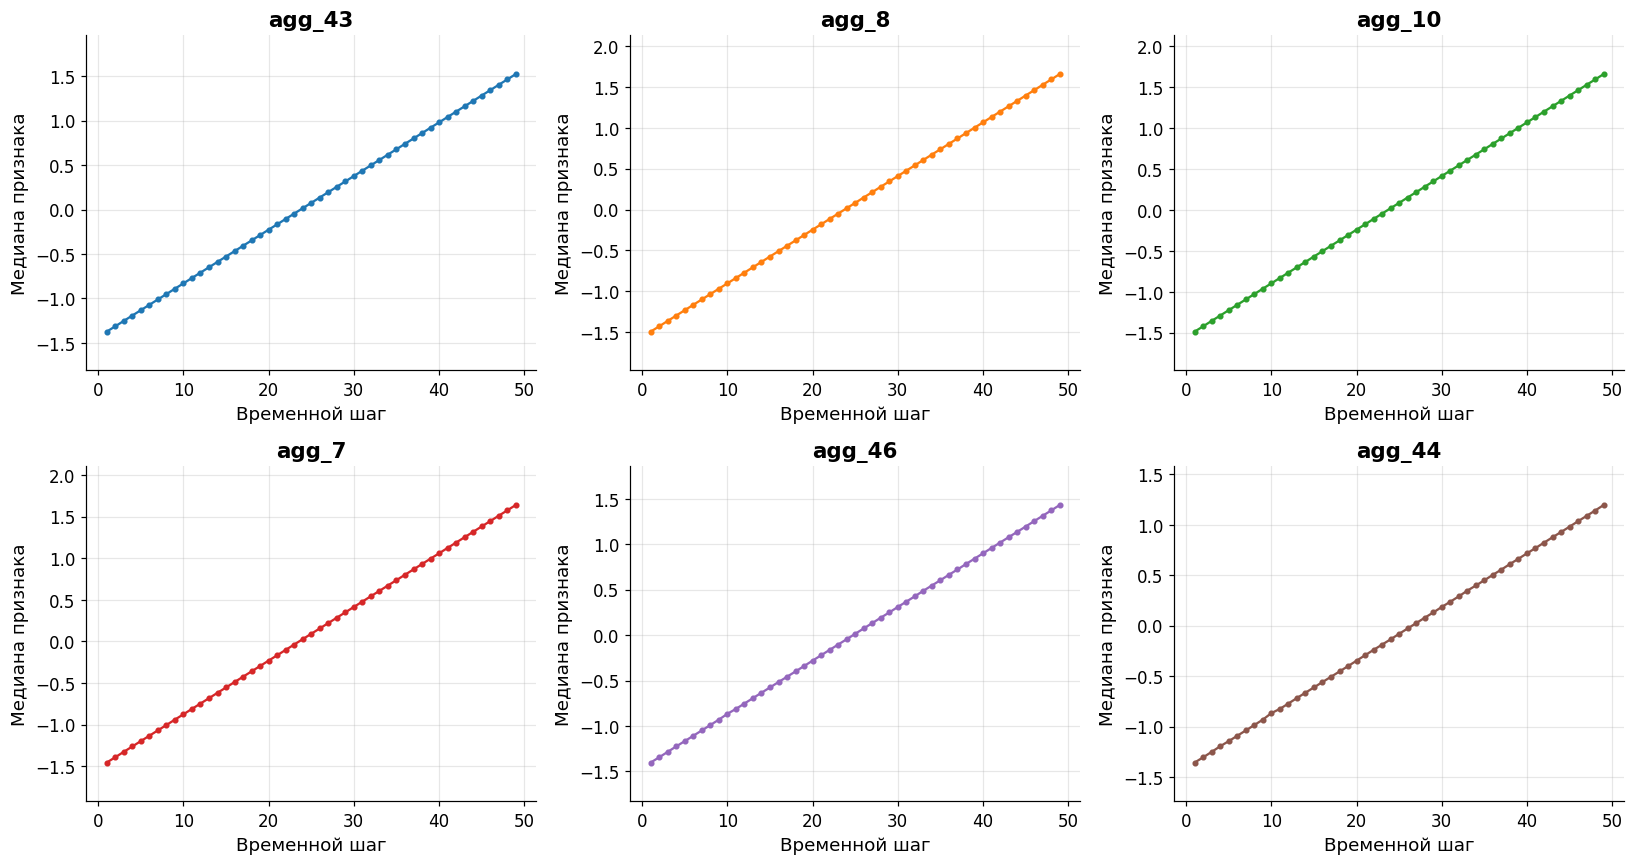

In [29]:
medians = df.groupby("time_step")[strange].median()

axes = medians.plot(subplots=True, layout=(2, 3), figsize=(15, 8), sharex=False,
                    marker="o", markersize=3, legend=False)

for ax, feature in zip(axes.flatten(), strange):
    ax.set_title(feature)
    ax.set_xlabel("Временной шаг")
    ax.set_ylabel("Медиана признака")

plt.tight_layout()
plt.show()

Медиана всех шести признаков растёт идеально ровной линией. Это больше похоже на сам номер шага. Проверим это через корреляцию с `time_step`.

In [30]:
time_corr = df[FEATURES].corrwith(df["time_step"])
# берём модуль
time_corr = time_corr.abs().sort_values(ascending=False)

time_corr.head(10)

agg_8      0.994448
agg_10     0.992579
agg_7      0.982430
agg_43     0.911859
agg_46     0.890583
agg_44     0.788108
agg_22     0.580025
local_3    0.573155
agg_58     0.571132
agg_19     0.562550
dtype: float64

У первых шести признаков корреляция от 0.79 до 0.99, а дальше резкий обрыв до 0.58. Но у части признаков она ниже, чем можно ожидать по идеально ровным графикам. Корреляция Пирсона чувствительна к выбросам, поэтому посмотрим ещё корреляцию Спирмена. Она сравнивает не сами значения, а их порядок, и выбросы на неё почти не влияют.

In [31]:
time_corr_spearman = df[FEATURES].corrwith(df["time_step"], method="spearman")
time_corr_spearman = time_corr_spearman.abs().sort_values(ascending=False)

time_corr_spearman.head(10)

agg_8      0.997643
agg_10     0.996520
agg_7      0.995038
agg_43     0.994883
agg_46     0.970433
agg_44     0.901884
local_2    0.630863
agg_13     0.603780
agg_16     0.603573
agg_14     0.570641
dtype: float64

По Спирмену у этих шести признаков корреляция от 0.90 до 0.99, а у следующего уже 0.63.

Посмотрим на сами значения

In [32]:
df[["time_step"] + strange].sample(10, random_state=42).sort_values("time_step")

,time_step,agg_43,agg_8,agg_10,agg_7,agg_46,agg_44
16006,3,-1.253084,-1.362709,-1.354981,-1.328785,-1.273486,-1.226776
26188,5,-1.132237,-1.231329,-1.223958,-1.199584,-1.157091,-1.123787
28018,5,-1.132296,-1.231622,-1.224251,-1.199872,-1.166000,-1.139749
45400,8,-0.951174,-1.048784,-1.361049,-3.772772,-0.990587,-0.983659
125292,31,0.438007,0.475768,0.478497,0.479192,0.421479,0.333387
128361,32,0.498191,0.541133,0.543684,0.543473,0.426827,0.290085
139710,35,0.679613,0.738431,0.740445,0.737498,0.604188,0.449415
169766,42,2.053276,1.198034,1.198799,1.189476,2.057206,1.853725
180721,44,1.223098,1.329284,1.329692,1.318549,1.136171,0.927905
196048,47,1.426119,1.526159,1.526032,1.512157,1.734863,1.825673


**Что видим в таблице:**

- Чем больше номер шага, тем больше значения всех шести признаков. На 3-м шаге они около -1.3, на 31-м около 0.45, на 47-м около 1.5.
- У двух транзакций с 5-го шага значения почти совпадают, различие только в третьем-четвёртом знаке после запятой.
- Иногда встречаются выбросы. У транзакции с 8-го шага `agg_7` равен -3.77, хотя у остальных признаков около -1. А на 42-м шаге `agg_43`, `agg_46` и `agg_44` около 2, хотя `agg_8` и `agg_10` около 1.2.

Получается, что значения этих признаков в основном определяются номером шага, а редкие выбросы как раз объясняют, почему корреляция Пирсона у части признаков ниже, чем у Спирмена.

In [33]:
# стандартизация: вычитаем среднее и делим на стандартное отклонение
time_scaled = (df["time_step"] - df["time_step"].mean()) / df["time_step"].std()

comparison = pd.DataFrame({"time_step": df["time_step"],
                           "time_step стандартиз.": time_scaled})

for feature in strange:
    comparison[feature] = df[feature]

comparison.groupby("time_step").median().head(10)

,time_step стандартиз.,agg_43,agg_8,agg_10,agg_7,agg_46,agg_44
time_step,,,,,,,
1,-1.505649,-1.373812,-1.494057,-1.486037,-1.458049,-1.403801,-1.354866
2,-1.439739,-1.313478,-1.428497,-1.420655,-1.393545,-1.345208,-1.302661
3,-1.373829,-1.253084,-1.362774,-1.355095,-1.328945,-1.285970,-1.249217
4,-1.307918,-1.192690,-1.297149,-1.289665,-1.264376,-1.225150,-1.192982
5,-1.242008,-1.132267,-1.231492,-1.224153,-1.199776,-1.167748,-1.142910
6,-1.176098,-1.072052,-1.165899,-1.158707,-1.135240,-1.108696,-1.089756
7,-1.110188,-1.011419,-1.100209,-1.093195,-1.070639,-1.049588,-1.036839
8,-1.044278,-0.951025,-1.034584,-1.027749,-1.006135,-0.990308,-0.983369
9,-0.978368,-0.890631,-0.968894,-0.962237,-0.941503,-0.931173,-0.930057


In [34]:
# медианы по шагам
step_medians = comparison.groupby("time_step").median()
step_medians.diff().mean().round(3)

time_step стандартиз.    0.066
agg_43                   0.060
agg_8                    0.066
agg_10                   0.065
agg_7                    0.065
agg_46                   0.059
agg_44                   0.053
dtype: float64

**Что видим в таблице:**

- Медианы всех шести признаков растут от шага к шагу почти на одну и ту же величину.
- У `agg_8`, `agg_10` и `agg_7` значения почти совпадают со стандартизированным номером шага, разница не больше 0.05.

Значит, все шесть признаков почти полностью определяются номером шага, просто каждый в своём масштабе.

Получается, что эти признаки описывают не саму транзакцию, а фактически момент времени. Из-за этого их нельзя использовать в модели по той же причине, что и `time_step`. Модель может запомнить, в какие периоды было много незаконных транзакций, а на тестовых шагах у этих признаков будут значения, которых она не видела при обучении.

Дальше в анализе дрейфа эти шесть признаков не рассматриваются.

### Дрейф остальных признаков

Убираем шесть признаков, которые кодируют время, и смотрим, какие признаки сильнее всего дрейфуют среди оставшихся.

In [35]:
real_drift = drift[~drift["feature"].isin(strange)]

real_drift.head(15)

,feature,KS
1,local_2,0.604995
105,agg_13,0.573018
108,agg_16,0.556302
106,agg_14,0.533597
141,agg_49,0.511467
111,agg_19,0.485940
114,agg_22,0.472537
2,local_3,0.469738
147,agg_55,0.461056
150,agg_58,0.457536


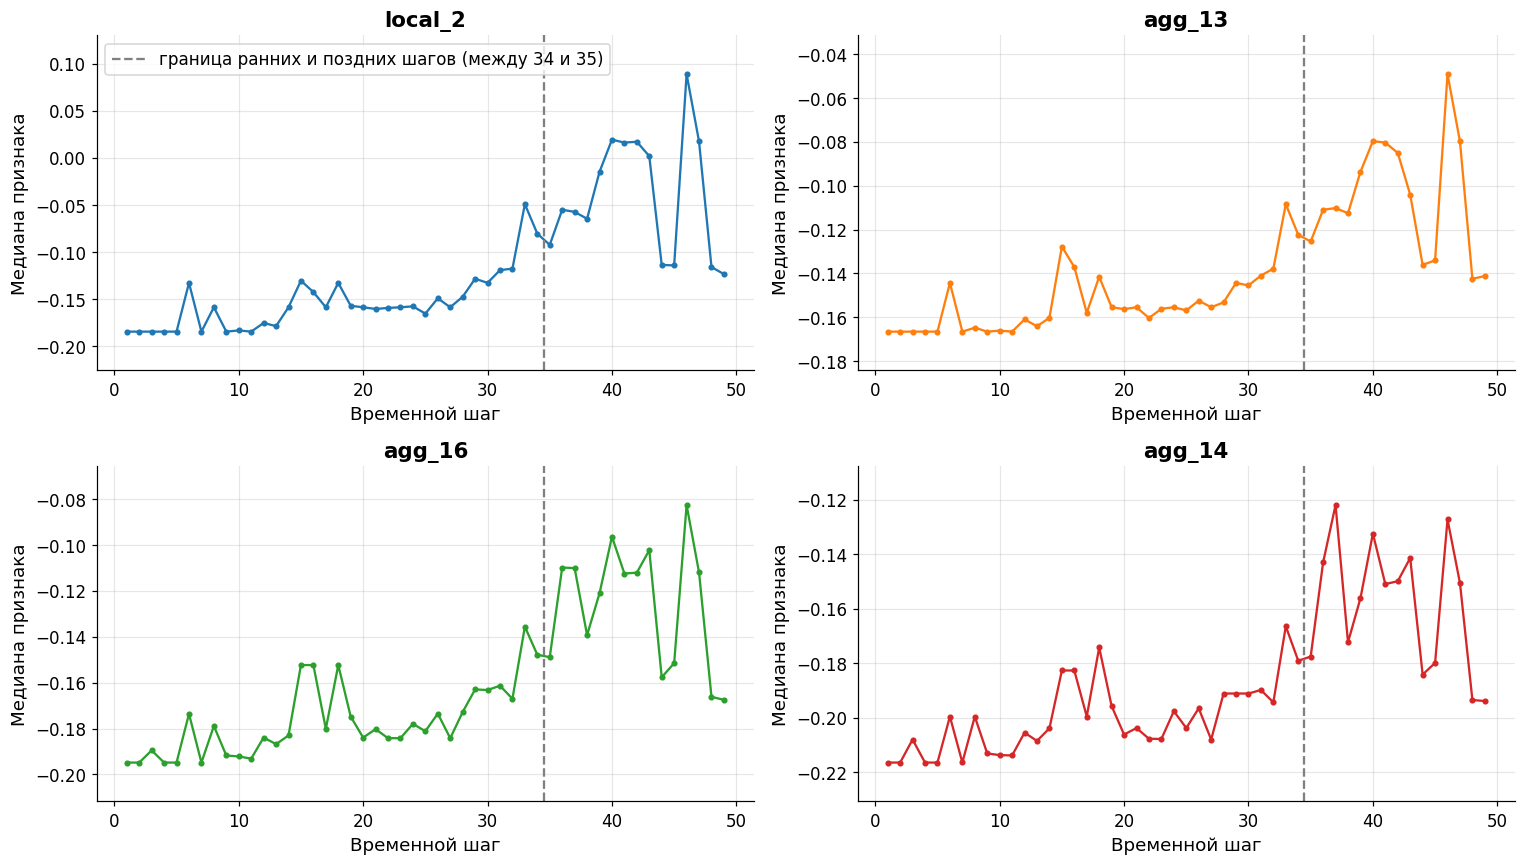

In [36]:
top_features = list(real_drift["feature"].head(4))

medians = df.groupby("time_step")[top_features].median()

axes = medians.plot(subplots=True, layout=(2, 2), figsize=(14, 8), sharex=False,
                    marker="o", markersize=3, legend=False)

for ax, feature in zip(axes.flatten(), top_features):
    ax.set_title(feature)
    border = ax.axvline(34.5, color="gray", linestyle="--",
                        label="граница ранних и поздних шагов (между 34 и 35)")
    ax.set_xlabel("Временной шаг")
    ax.set_ylabel("Медиана признака")

axes.flatten()[0].legend(handles=[border])
plt.tight_layout()
plt.show()

**Что видим на графике:**

- На ранних шагах медиана всех четырёх признаков почти не меняется. Есть отдельные всплески (около 6-8 и 15-18 шагов), но потом значения возвращаются обратно.
- Примерно с 25-го шага медиана начинает постепенно расти, а после границы периодов поднимается заметно выше, чем было на ранних шагах.
- На поздних шагах значения сильно скачут. Пики приходятся примерно на шаги 40-43 и 46, а к последним шагам медиана снова опускается, хотя у большинства признаков остаётся выше, чем в начале.

Все четыре признака меняются почти одинаково, возможно они описывают похожие характеристики транзакций. В отличие от шести признаков с KS больше 0.9, здесь нет ровной прямой, значения меняются неравномерно и со скачками. Это больше похоже на реальное изменение транзакций со временем, то есть на настоящий дрейф.


### Дрейф признаков отдельно для licit и illicit

Общий KS смешивает две вещи. Признак может сдвинуться потому, что изменились сами транзакции, а может потому, что на поздних шагах другое соотношение классов. Мы уже видели, что illicit на поздних шагах меньше. Если licit и illicit сильно отличаются по признаку, то одно только изменение их доли уже сдвинет общее распределение, даже если внутри каждого класса ничего не поменялось.

Чтобы разделить эти эффекты, посчитаем KS между ранними и поздними шагами отдельно для licit и отдельно для illicit. Дрейф внутри illicit особенно важен. Он может значить, что незаконные транзакции со временем стали выглядеть иначе, и модель, обученная на старых схемах, будет хуже находить новые.

Шесть признаков, повторяющих номер шага, здесь тоже не рассматриваем.

In [37]:
features_no_time = [f for f in FEATURES if f not in strange]

early_licit = early[early["label"] == "licit"]
late_licit = late[late["label"] == "licit"]
early_illicit = early[early["label"] == "illicit"]
late_illicit = late[late["label"] == "illicit"]

print(f"licit: ранних {len(early_licit)}, поздних {len(late_licit)}")
print(f"illicit: ранних {len(early_illicit)}, поздних {len(late_illicit)}")

licit: ранних 26432, поздних 15587
illicit: ранних 3462, поздних 1083


In [38]:
class_drift = []

for feature in features_no_time:
    class_drift.append({
        "feature": feature,
        "KS licit": ks_2samp(early_licit[feature], late_licit[feature]).statistic,
        "KS illicit": ks_2samp(early_illicit[feature], late_illicit[feature]).statistic,
    })

class_drift = pd.DataFrame(class_drift)

# добавляем общий KS из таблицы drift, чтобы сравнить
class_drift = class_drift.merge(drift, on="feature").rename(columns={"KS": "KS общий"})

class_drift.sort_values("KS illicit", ascending=False).head(15).round(3)

,feature,KS licit,KS illicit,KS общий
1,local_2,0.644,0.741,0.605
105,agg_16,0.556,0.649,0.556
103,agg_14,0.478,0.639,0.534
102,agg_13,0.622,0.556,0.573
2,local_3,0.448,0.463,0.470
136,agg_50,0.336,0.461,0.306
138,agg_52,0.369,0.457,0.327
109,agg_20,0.375,0.418,0.434
111,agg_22,0.504,0.397,0.473
142,agg_56,0.319,0.384,0.292


In [39]:
# сколько признаков попадает в каждый диапазон KS
bins = [0, 0.1, 0.2, 0.4, 1.01]
level_names = ["< 0.1", "0.1-0.2", "0.2-0.4", ">= 0.4"]

drift_levels = pd.DataFrame()

for col in ["KS общий", "KS licit", "KS illicit"]:
    levels = pd.cut(class_drift[col], bins=bins, labels=level_names, right=False)
    drift_levels[col] = levels.value_counts().sort_index()

drift_levels

,KS общий,KS licit,KS illicit
KS общий,,,
< 0.1,105,60,73
0.1-0.2,34,73,47
0.2-0.4,9,16,31
>= 0.4,11,10,8


**Что видим в таблицах:**

- Внутри licit и illicit признаки дрейфуют не меньше, чем в целом. Например, у `local_2` общий KS 0.61, у licit 0.64, а у illicit 0.74.
- Сильнее всего меняются те же признаки, что и в целом, это `local_2`, `agg_13`, `agg_14`, `agg_16` и `local_3`.
- У illicit заметный дрейф (KS от 0.2) у 39 признаков, у licit у 26, а в целом у 20.

Если бы дрейф был только из-за того, что на поздних шагах меньше незаконных транзакций, внутри licit и illicit признаки почти не менялись бы. Но они меняются не меньше, чем в целом. Значит, со временем меняются сами транзакции обоих классов.

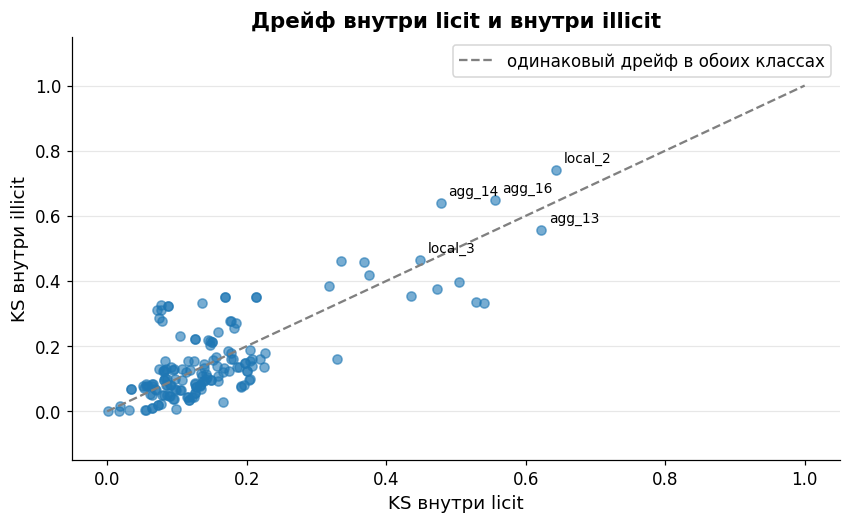

In [40]:
plt.scatter(class_drift["KS licit"], class_drift["KS illicit"], alpha=0.6)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="одинаковый дрейф в обоих классах")

for _, row in class_drift.sort_values("KS illicit", ascending=False).head(5).iterrows():
    plt.annotate(row["feature"], (row["KS licit"], row["KS illicit"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)

plt.title("Дрейф внутри licit и внутри illicit")
plt.xlabel("KS внутри licit")
plt.ylabel("KS внутри illicit")
plt.legend()
plt.show()

Точки выше диагонали - признаки, которые сильнее меняются у незаконных транзакций, ниже - у легальных.

**Что видим на графике:**

- Большинство точек лежит недалеко от диагонали, то есть обычно признак дрейфует в обоих классах примерно одинаково.
- Признаки с самым сильным дрейфом (`local_2`, `agg_13`, `agg_14`, `agg_16`) сильно меняются и у licit, и у illicit.
- Выше диагонали есть группа точек, у которых KS внутри licit около 0.1, а внутри illicit около 0.3. Это признаки, которые меняются в основном у незаконных транзакций.

**Итого по дрейфу:**

Большинство признаков со временем меняются мало, у 139 из 165 KS меньше 0.2. Но у 20 признаков дрейф заметный, а самые дрейфующие из них после 25-го шага постепенно растут и особенно сильно меняются после границы периодов.

Отдельно стоят шесть признаков с KS больше 0.9. Они почти полностью повторяют номер временного шага, поэтому в модели их использовать нельзя, как и сам `time_step`.

Для моделирования это значит, что делить данные на train и test нужно по времени, а качество модели на поздних шагах, скорее всего, будет хуже, чем на ранних. Поэтому на тесте стоит смотреть метрики не только в целом, но и по отдельным шагам.

Также дрейф есть и внутри licit, и внутри illicit, причём не меньше, чем в целом. У незаконных транзакций дрейфует даже больше признаков. Получается, что на тесте модели встретятся незаконные транзакции, которые выглядят не так, как те, на которых она училась.

## 4. Temporal train/test split

Данные со временем меняются, поэтому делить их на train и test случайно нельзя. Иначе в обучение попадут транзакции из "будущего", и качество модели на тесте окажется завышенным. Делим по времени, как в статье про датасет ([Weber and Domeniconi, et al., 2019](https://arxiv.org/abs/1908.02591)). Шаги 1-34 идут в train, шаги 35-49 в test. Так модель учится на прошлом и проверяется на будущем, как это и происходит в реальной работе.

In [41]:
train = df[df["time_step"] <= 34]
test = df[df["time_step"] >= 35]

print(f"Train (шаги 1-34): {len(train)} транзакций ({len(train) / len(df):.1%})")
print(f"Test (шаги 35-49): {len(test)} транзакций ({len(test) / len(df):.1%})")

Train (шаги 1-34): 136265 транзакций (66.9%)
Test (шаги 35-49): 67504 транзакций (33.1%)


Посмотрим, сколько транзакций каждого типа попало в train и test.

In [42]:
split_table = pd.DataFrame({
    "train": train["label"].value_counts()[classes],
    "доля в train": train["label"].value_counts(normalize=True)[classes].round(3),
    "test": test["label"].value_counts()[classes],
    "доля в test": test["label"].value_counts(normalize=True)[classes].round(3),
})

split_table

,train,доля в train,test,доля в test
label,,,,
illicit,3462,0.025,1083,0.016
licit,26432,0.194,15587,0.231
unknown,106371,0.781,50834,0.753


Теперь уберём unknown и посмотрим на соотношение illicit и licit среди размеченных транзакций в train и test. Именно на них модель будет учиться и проверяться.

In [43]:
labeled_classes = ["illicit", "licit"]

train_labeled = train[train["label"] != "unknown"]
test_labeled = test[test["label"] != "unknown"]

split_labeled_table = pd.DataFrame({
    "train": train_labeled["label"].value_counts()[labeled_classes],
    "доля в train": train_labeled["label"].value_counts(normalize=True)[labeled_classes].round(3),
    "test": test_labeled["label"].value_counts()[labeled_classes],
    "доля в test": test_labeled["label"].value_counts(normalize=True)[labeled_classes].round(3),
})

split_labeled_table

,train,доля в train,test,доля в test
label,,,,
illicit,3462,0.116,1083,0.065
licit,26432,0.884,15587,0.935


In [44]:
print(f"Размеченных в train: {len(train_labeled)}")
print(f"Размеченных в test: {len(test_labeled)}")

Размеченных в train: 29894
Размеченных в test: 16670


**Что видим в таблицах:**

- В train попало 29 894 размеченные транзакции, в test 16 670. Неразмеченных в обеих частях примерно одинаково, около трёх четвертей.
- Доля illicit среди размеченных в train 11.6%, а в test всего 6.5%, почти в два раза меньше. Так получается потому, что с 43-го шага незаконных транзакций становится очень мало, а все эти шаги попадают в test.

Из-за этого тест для модели будет сложнее. Незаконных транзакций там меньше, и они могут отличаться от тех, что были в обучении. Кроме того, precision и PR-AUC зависят от того, насколько часто встречается illicit, так что на тесте эти метрики наверняка окажутся ниже, чем на train, даже у хорошей модели.

## 5. Выводы

**Метки.** Размечено 46 564 транзакции, это около 23% датасета, остальные 77% - unknown. Это единственные пропуски в данных, и они не случайны. Метки ставили только транзакциям, которые удалось связать с известными участниками, и unknown по признакам заметно отличаются от размеченных. Среди размеченных незаконных 9.8%, то есть классы сильно несбалансированы. Поэтому accuracy для оценки не подходит, нужно смотреть на precision, recall, F1 и PR-AUC по классу illicit.

**Время.** Число транзакций и доля незаконных сильно меняются от шага к шагу. На первых шагах illicit почти нет, в середине их доля доходит до 30% и выше, а с 43-го шага резко падает почти до нуля и только к последним шагам снова немного поднимается.

**Дрейф.** Был использован тест Колмогорова-Смирнова, который показывает, насколько сильно меняется каждый признак между ранними и поздними шагами. У 139 из 165 признаков разница небольшая, то есть со временем они меняются мало. Но у части признаков дрейф заметный, они растут после 25-го шага и особенно сильно меняются на поздних шагах. Шесть признаков почти полностью повторяют номер временного шага, в модели их использовать нельзя. Дрейф есть и внутри licit, и внутри illicit, так что со временем меняется не только доля незаконных транзакций, но и сами транзакции. У illicit заметно дрейфует даже больше признаков, чем у licit.

**Разбиение.** Делим данные по времени, шаги 1-34 идут в train, шаги 35-49 в test. В test доля illicit среди размеченных почти в два раза меньше, чем в train, поэтому метрики на тесте, скорее всего, будут ниже.

**На что обратить внимание при обучении моделей:**

- использовать 159 признаков, без `time_step` и шести признаков, повторяющих номер шага.
- учитывать дисбаланс классов.
- оценивать качество не только на всём тесте, но и по отдельным шагам, чтобы видеть, где модель начинает ошибаться.